# Neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anatole-1/exercices-machine-learning/blob/main/04_neural_networks.ipynb)

1. Exercise 1 – Four interleaved spirals (4 classes)
2. Exercise 2 – Apple quality (binary classification)
3. Exercise 3 – Dry beans (7 classes)
4. Exercise 4 – Sign Language MNIST with a dense network
5. Exercise 5 – Car prices (MSRP regression)

Run the notebook from the repository folder (the data files are in `data/`). In Google Colab, the first code cell clones the repository automatically.

In [ ]:
# Google Colab: get the data files by cloning the repository
import os, subprocess
if 'google.colab' in str(get_ipython()) and not os.path.exists('data'):
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/Anatole-1/exercices-machine-learning.git'], check=True)
    os.chdir('exercices-machine-learning')

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng=np.random.default_rng() #seed = random

## Exercise 1


Build and train a neural network with one hidden layer that achieves $\approx 100 \%$ classification accuracy for datapoints $x^{(i)}=[x_1^{(i)},x_2^{(i)}],\,y^{(i)}=0,1,2,3$, below.

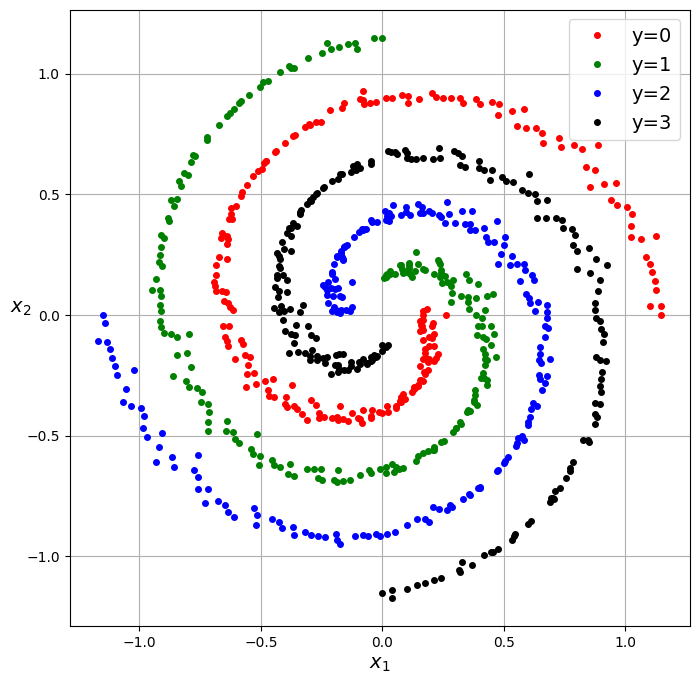

In [ ]:
n=200
m=4*n #number of datapoints
th=np.linspace(0,2*np.pi,n)
r=np.linspace(0.15,1.15,n)
e=rng.normal(0,0.02,n)

x11=r*np.cos(-th)+e
x12=r*np.sin(-th)+e

x21=r*np.cos(np.pi/2-th)+e
x22=r*np.sin(np.pi/2-th)+e

x31=r*np.cos(np.pi-th)+e
x32=r*np.sin(np.pi-th)+e

x41=r*np.cos(3*np.pi/2-th)+e
x42=r*np.sin(3*np.pi/2-th)+e

plt.figure(figsize=(8,8))
plt.plot(x11,x12,'r.',markersize=8,label='y=0')
plt.plot(x21,x22,'g.',markersize=8,label='y=1')
plt.plot(x31,x32,'b.',markersize=8,label='y=2')
plt.plot(x41,x42,'k.',markersize=8,label='y=3')
plt.grid()
plt.xlabel('$x_1$',fontsize=14)
plt.ylabel('$x_2$',fontsize=14,rotation=0)
plt.legend(fontsize=14)
plt.show()

In [ ]:
#datapoints as rows of matrix x
x1=np.hstack((x11,x21,x31,x41))
x2=np.hstack((x12,x22,x32,x42))
x=np.vstack((x1,x2)).T

#classes in 1D-array y
y0=np.zeros(n)
y1=np.ones(n)
y2=2*np.ones(n)
y3=3*np.ones(n)
y=np.hstack((y0,y1,y2,y3))

print(x.shape)
print(y.shape)

(800, 2)
(800,)


In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.optimizers import Adam

N=300

model=Sequential()
model.add(Input(shape=(2,)))
model.add(Dense(N, activation='relu'))
model.add(Dense(4, activation='softmax'))

model.summary()

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history=model.fit(x,y,
                  epochs=1000,
                  batch_size=800,
                  verbose=0)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 300)            │           900 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         1,204 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,104 (8.22 KB)

 Trainable params: 2,104 (8.22 KB)

 Non-trainable params: 0 (0.00 B)

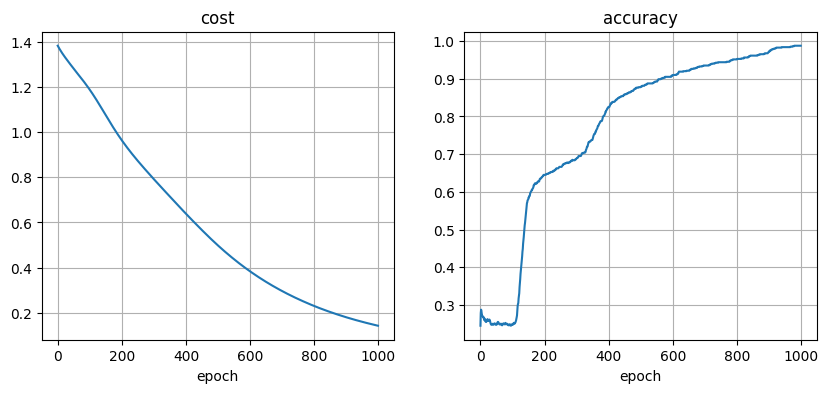

accuracy = 0.987500011920929


In [ ]:
cost=history.history['loss']
acc=history.history['accuracy']

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(cost)
plt.grid()
plt.title('cost')
plt.xlabel('epoch')

plt.subplot(1,2,2)
plt.plot(acc)
plt.grid()
plt.title('accuracy')
plt.xlabel('epoch')

plt.show()

loss, accuracy=model.evaluate(x,y,verbose=0)
print('accuracy =', accuracy)

Calculate the confusion matrix

![figure](images/04_ex1_1.png)

In [ ]:
from sklearn.metrics import confusion_matrix

ypred=np.argmax(model.predict(x,verbose=0),axis=1)
confusion_matrix(y,ypred)

array([[196,   4,   0,   0],
       [  0, 200,   0,   0],
       [  0,   0, 198,   2],
       [  4,   0,   0, 196]])

draw a picture like below of the resulting classification

![figure](images/04_ex1_2.png)

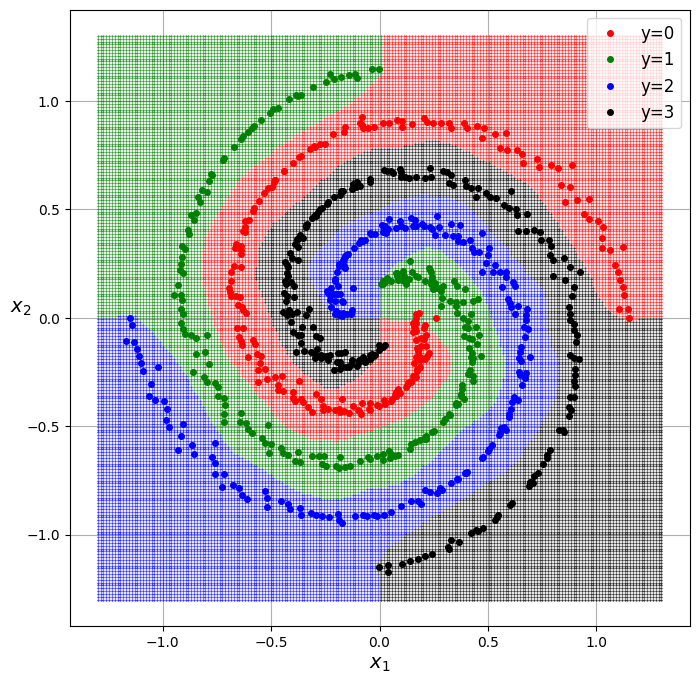

In [ ]:
M=200
xx1=np.linspace(-1.3,1.3,M)
xx2=np.linspace(-1.3,1.3,M)
XX1,XX2=np.meshgrid(xx1,xx2)

X1=XX1.reshape((M*M,1))
X2=XX2.reshape((M*M,1))
X=np.hstack((X1,X2))

A=model.predict(X,verbose=0)
Ypred=np.argmax(A,axis=1).reshape((M,M))

plt.figure(figsize=(8,8))

plt.plot(XX1[Ypred==0],XX2[Ypred==0],'r.',markersize=1)
plt.plot(XX1[Ypred==1],XX2[Ypred==1],'g.',markersize=1)
plt.plot(XX1[Ypred==2],XX2[Ypred==2],'b.',markersize=1)
plt.plot(XX1[Ypred==3],XX2[Ypred==3],'k.',markersize=1)

plt.plot(x[y==0,0],x[y==0,1],'ro',markersize=4,label='y=0')
plt.plot(x[y==1,0],x[y==1,1],'go',markersize=4,label='y=1')
plt.plot(x[y==2,0],x[y==2,1],'bo',markersize=4,label='y=2')
plt.plot(x[y==3,0],x[y==3,1],'ko',markersize=4,label='y=3')

plt.grid()
plt.axis('equal')
plt.xlabel('$x_1$',fontsize=14)
plt.ylabel('$x_2$',fontsize=14,rotation=0)
plt.legend(fontsize=12)
plt.show()

and 3D-plots like below.

![figure](images/04_ex1_3.png)

![figure](images/04_ex1_4.png)

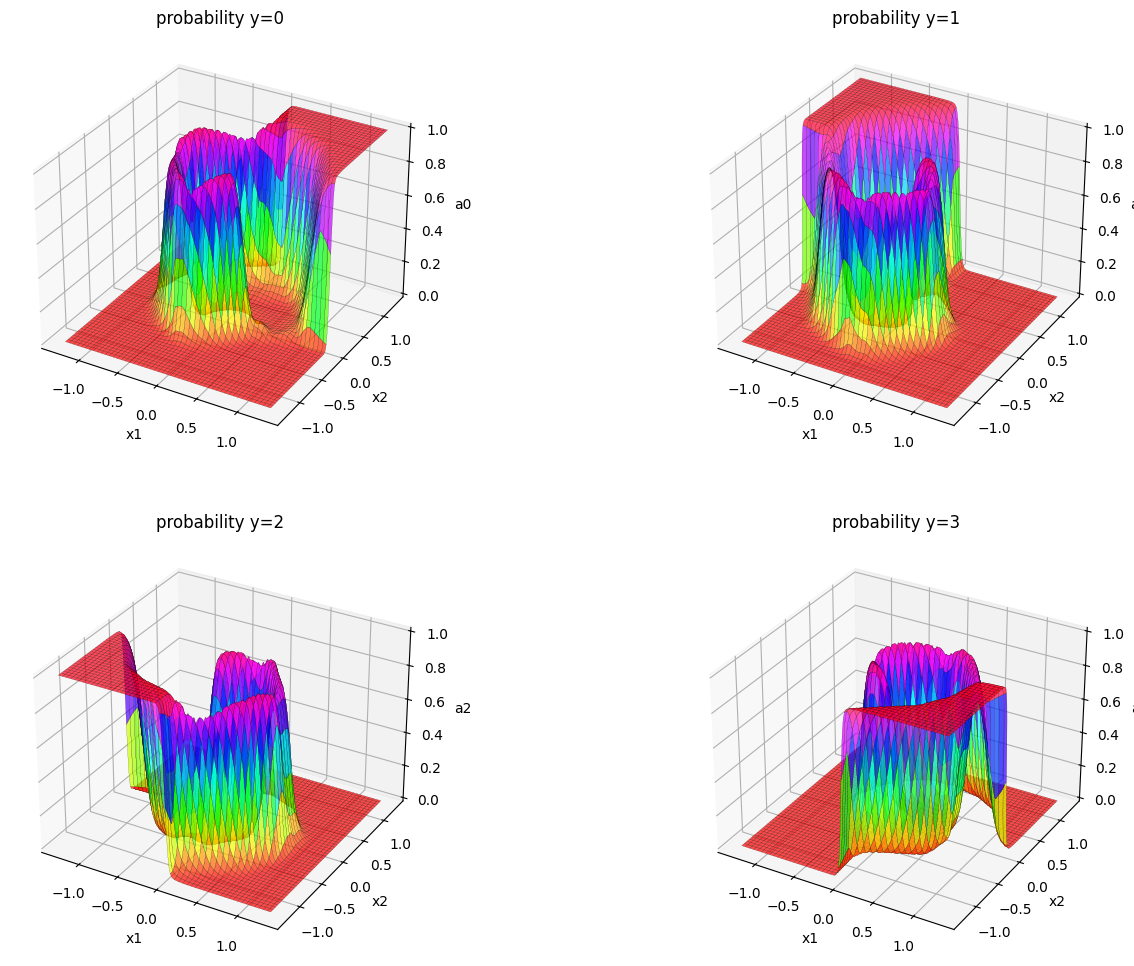

In [ ]:
from mpl_toolkits import mplot3d

A0=A[:,0].reshape((M,M))
A1=A[:,1].reshape((M,M))
A2=A[:,2].reshape((M,M))
A3=A[:,3].reshape((M,M))

fig=plt.figure(figsize=(16,12))

ax=fig.add_subplot(221, projection='3d')
ax.plot_surface(XX1,XX2,A0,cmap='hsv',edgecolor='k',linewidth=0.1,alpha=0.7)
ax.set_title('probability y=0')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('a0')

ax=fig.add_subplot(222, projection='3d')
ax.plot_surface(XX1,XX2,A1,cmap='hsv',edgecolor='k',linewidth=0.1,alpha=0.7)
ax.set_title('probability y=1')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('a1')

ax=fig.add_subplot(223, projection='3d')
ax.plot_surface(XX1,XX2,A2,cmap='hsv',edgecolor='k',linewidth=0.1,alpha=0.7)
ax.set_title('probability y=2')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('a2')

ax=fig.add_subplot(224, projection='3d')
ax.plot_surface(XX1,XX2,A3,cmap='hsv',edgecolor='k',linewidth=0.1,alpha=0.7)
ax.set_title('probability y=3')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('a3')

plt.show()

## Exercise 2


In [ ]:
#load data/apple_quality.csv
df=pd.read_csv('data/apple_quality.csv',index_col=0)
df.head() #first 5 rows

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
A_id,,,,,,,,
0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590,good
1,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809,good
2,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636,bad
3,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723,good
4,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984,good


Goal: to predict Quality using the other 7 variables Size ... Acidity

Split datapoints to training and test (70%/30%), and build and train a neural network with one hidden layer that achieves 93% classification accuracy for test data, and calculate the confusion matrix.

In [ ]:
#coordinates and Quality to numpy arrays
X=np.array(df.iloc[:,:7])

#Quality: good -> 1, bad -> 0
y=np.zeros(df.shape[0])
y[df['Quality']=='good']=1

print(X.shape)
print(y.shape)

(4000, 7)
(4000,)


In [ ]:
#split datapoints to training and test/validation (70%/30%)
from sklearn.model_selection import train_test_split

Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,test_size=0.3,random_state=0)

#normalize training data
mu=np.mean(Xtrain,axis=0)
sigma=np.std(Xtrain,axis=0)

Xtrain_hat=(Xtrain-mu)/sigma
Xtest_hat=(Xtest-mu)/sigma

print(mu)
print(sigma)

[-0.48462744 -1.01850597 -0.46889081  1.003816    0.51211731  0.50829159
  0.06479533]
[1.93120392 1.58429855 1.93568835 1.4000574  1.92550321 1.88179125
 2.09505386]


In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint

N=100

model=Sequential()
model.add(Input(shape=(7,)))
model.add(Dense(N,activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(1,activation='sigmoid'))

model.summary()

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

callback=ModelCheckpoint(
    filepath='apple_weights.weights.h5',
    monitor='val_accuracy',
    mode='max',
    save_weights_only=True,
    save_best_only=True,
    verbose=1)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 100)            │           800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 901 (3.52 KB)

 Trainable params: 901 (3.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history=model.fit(Xtrain_hat,ytrain,
                  epochs=500,
                  batch_size=280,
                  validation_data=(Xtest_hat,ytest),
                  callbacks=[callback])

Epoch 1/500
 1/10 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.5429 - loss: 0.7195
Epoch 1: val_accuracy improved from None to 0.62667, saving model to apple_weights.weights.h5

Epoch 1: finished saving model to apple_weights.weights.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - accuracy: 0.5839 - loss: 0.6864 - val_accuracy: 0.6267 - val_loss: 0.6591
Epoch 2/500
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6107 - loss: 0.6601
Epoch 2: val_accuracy improved from 0.62667 to 0.66083, saving model to apple_weights.weights.h5

Epoch 2: finished saving model to apple_weights.weights.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6614 - loss: 0.6344 - val_accuracy: 0.6608 - val_loss: 0.6233
Epoch 3/500
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.6750 - loss: 0.6213
Epoch 3: val_accuracy improved from 0.66083 to 0.70167, saving model to apple_weights.weights.h5

Epoch 3: finished saving model to apple_weights.weights.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - a

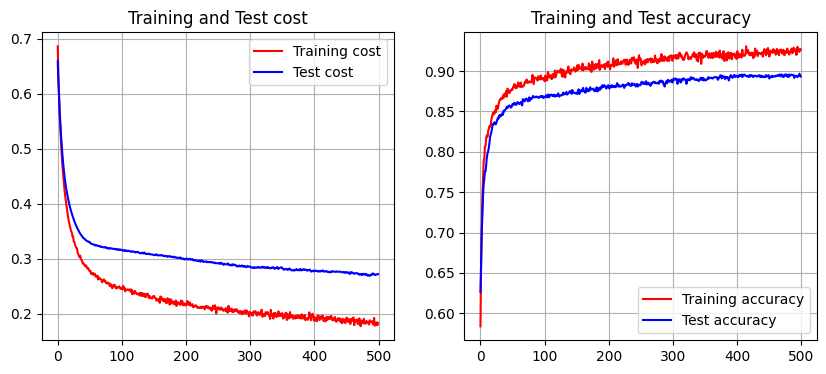

In [ ]:
train_cost=history.history['loss']
test_cost=history.history['val_loss']
train_acc=history.history['accuracy']
test_acc=history.history['val_accuracy']

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_cost,'r',label='Training cost')
plt.plot(test_cost,'b',label='Test cost')
plt.grid()
plt.legend()
plt.title('Training and Test cost')

plt.subplot(1,2,2)
plt.plot(train_acc,'r',label='Training accuracy')
plt.plot(test_acc,'b',label='Test accuracy')
plt.grid()
plt.legend()
plt.title('Training and Test accuracy')

plt.show()

In [ ]:
#load best weights
model.load_weights('apple_weights.weights.h5')

train_loss,train_acc=model.evaluate(Xtrain_hat,ytrain,verbose=0)
test_loss,test_acc=model.evaluate(Xtest_hat,ytest,verbose=0)

print('train accuracy =',train_acc)
print('test accuracy =',test_acc)

train accuracy = 0.9353571534156799
test accuracy = 0.8966666460037231


![figure](images/04_ex2_1.png)

In [ ]:
from sklearn.metrics import confusion_matrix

atest_pred=model.predict(Xtest_hat,verbose=0)[:,0]

mtest=ytest.shape[0]
ytest_pred=np.zeros(mtest)
ytest_pred[atest_pred>=0.5]=1

confusion_matrix(ytest,ytest_pred)

array([[543,  69],
       [ 55, 533]])

Classify the apple
xt=[ 1.34470668, -0.08934453, -4.50875321,  0.59093255, -3.98352604,
        1.50052136, -0.28032534]

(ans. bad)        

In [ ]:
xt=np.array([[ 1.34470668, -0.08934453, -4.50875321,  0.59093255, -3.98352604,
        1.50052136, -0.28032534]])

xt_hat=(xt-mu)/sigma

at=model.predict(xt_hat,verbose=0)[0,0]

print('probability good =',at)

if at>=0.5:
    print('good')
else:
    print('bad')

probability good = 0.38166773
bad


## Exercise 3


In [ ]:
#load data/Dry_Bean_Dataset.csv
df=pd.read_csv('data/Dry_Bean_Dataset.csv')
df.shape

(13611, 17)

In [ ]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Goal: to predict the class using the other variables.


Split datapoints to training and test (70%/30%), build and train a neural network with one hidden layer that achieves $\approx$ 93% classification accuracy for test data, calculate the confusion matrix

In [ ]:
#coordinates and Class to numpy arrays
X=np.array(df.iloc[:,:16])

classes=df['Class'].unique()
print(classes)

y=np.zeros(df.shape[0])

for k in range(classes.size):
    y[df['Class']==classes[k]]=k

print(X.shape)
print(y.shape)

['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']
(13611, 16)
(13611,)


In [ ]:
from sklearn.model_selection import train_test_split

Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,test_size=0.3,random_state=0)

#normalize training data
mu=np.mean(Xtrain,axis=0)
sigma=np.std(Xtrain,axis=0)

Xtrain_hat=(Xtrain-mu)/sigma
Xtest_hat=(Xtest-mu)/sigma

print(mu)
print(sigma)

[5.33332346e+04 8.56963847e+02 3.20675209e+02 2.02760475e+02
 1.58210012e+00 7.50297872e-01 5.40536713e+04 2.53586051e+02
 7.50303551e-01 9.87190370e-01 8.73547106e-01 8.00230677e-01
 6.55322569e-03 1.71669247e-03 6.44204792e-01 9.95129248e-01]
[2.97912612e+04 2.17040431e+02 8.66284132e+01 4.56606328e+01
 2.47491958e-01 9.23910496e-02 3.02415807e+04 6.00008157e+01
 4.89421576e-02 4.63285685e-03 5.98256168e-02 6.19326679e-02
 1.13809180e-03 5.98566608e-04 9.93683055e-02 4.27898757e-03]


In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint

N=100

model=Sequential()
model.add(Input(shape=(16,)))
model.add(Dense(N,activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(7,activation='softmax'))

model.summary()

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callback=ModelCheckpoint(
    filepath='dry_bean_weights.weights.h5',
    monitor='val_accuracy',
    mode='max',
    save_weights_only=True,
    save_best_only=True,
    verbose=1)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 100)            │         1,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 7)              │           707 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,407 (9.40 KB)

 Trainable params: 2,407 (9.40 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history=model.fit(Xtrain_hat,ytrain,
                  epochs=500,
                  batch_size=1000,
                  validation_data=(Xtest_hat,ytest),
                  callbacks=[callback])

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.2820 - loss: 2.0174
Epoch 1: val_accuracy improved from None to 0.41895, saving model to dry_bean_weights.weights.h5

Epoch 1: finished saving model to dry_bean_weights.weights.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 204ms/step - accuracy: 0.3253 - loss: 1.9146 - val_accuracy: 0.4190 - val_loss: 1.6740
Epoch 2/500
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4130 - loss: 1.6743
Epoch 2: val_accuracy improved from 0.41895 to 0.61312, saving model to dry_bean_weights.weights.h5

Epoch 2: finished saving model to dry_bean_weights.weights.h5
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4965 - loss: 1.5290 - val_accuracy: 0.6131 - val_loss: 1.3597
Epoch 3/500
 1/10 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.5880 - loss: 1.3846
Epoch 3: val_accuracy improved from 0.61312 to 0.74388, saving model to dry_bean_weights.weights.h5

Epoch 3: finished saving model to dry_bean_weights.weights.h5
10/10 ━━━━━━━━━━━━━━━━

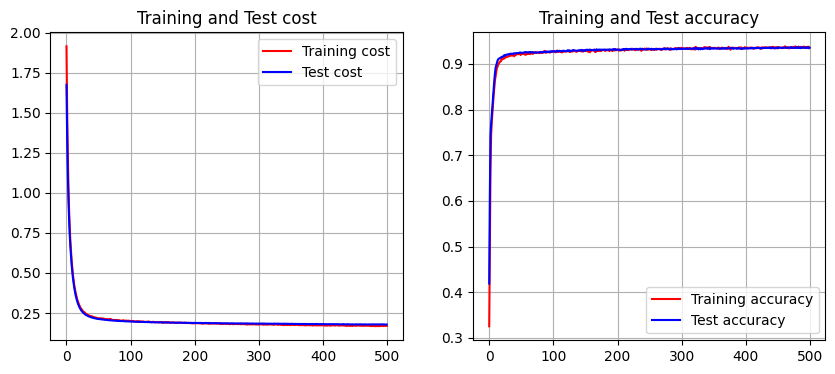

In [ ]:
train_cost=history.history['loss']
test_cost=history.history['val_loss']
train_acc=history.history['accuracy']
test_acc=history.history['val_accuracy']

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_cost,'r',label='Training cost')
plt.plot(test_cost,'b',label='Test cost')
plt.grid()
plt.legend()
plt.title('Training and Test cost')

plt.subplot(1,2,2)
plt.plot(train_acc,'r',label='Training accuracy')
plt.plot(test_acc,'b',label='Test accuracy')
plt.grid()
plt.legend()
plt.title('Training and Test accuracy')

plt.show()

In [ ]:
model.load_weights('dry_bean_weights.weights.h5')

train_loss,train_acc=model.evaluate(Xtrain_hat,ytrain,verbose=0)
test_loss,test_acc=model.evaluate(Xtest_hat,ytest,verbose=0)

print('train accuracy =',train_acc)
print('test accuracy =',test_acc)

train accuracy = 0.9397501945495605
test accuracy = 0.9368266463279724


![figure](images/04_ex3_1.png)

In [ ]:
from sklearn.metrics import confusion_matrix

atest_pred=model.predict(Xtest_hat,verbose=0)
ytest_pred=np.argmax(atest_pred,axis=1)

confusion_matrix(ytest,ytest_pred)

array([[552,   3,   0,   0,   0,  19,   5],
       [  3, 358,   0,  20,   2,   6,   0],
       [  0,   0, 134,   0,   0,   0,   0],
       [  2,   9,   0, 481,   6,   3,   0],
       [  0,   1,   0,   6, 575,   8,   4],
       [  4,   2,   0,   3,  15, 730,  76],
       [ 11,   1,   0,   0,   1,  48, 996]])

and classify the dry bean

xt=[29817        ,   654.94      ,   249.9393798 ,   153.5127658 ,
           1.62813417,     0.78915041, 30306        ,   194.8439979 ,
           0.76110374,     0.98386458,     0.87351583,     0.77956502,
           0.00838245,     0.00190968,     0.60772162,     0.98945234]

(ans. dermason)           

In [ ]:
xt=np.array([[29817        ,   654.94      ,   249.9393798 ,   153.5127658 ,
           1.62813417,     0.78915041, 30306        ,   194.8439979 ,
           0.76110374,     0.98386458,     0.87351583,     0.77956502,
           0.00838245,     0.00190968,     0.60772162,     0.98945234]])

xt_hat=(xt-mu)/sigma

at=model.predict(xt_hat,verbose=0)
yt_pred=np.argmax(at[0,:])

print(at)
print(classes[yt_pred])

[[6.5792568e-07 2.3569786e-08 2.2057262e-07 1.1335620e-08 2.2870118e-02
  5.2717449e-03 9.7185719e-01]]
DERMASON


## Exercise 4


[Sign-language-mnist-dataset](https://www.kaggle.com/datasets/datamunge/sign-language-mnist/code)

 28x28 bw-pictures of hand-gesture alphabets  A-Y (without J),
27455 training- and 7172 test.



![figure](images/04_ex4_1.png)







Build and train a neural network with one hidden layer that achieves 80% classification accuracy for test-data.

Calculate the predictions for a random test-picture and draw a picture like below.




![figure](images/04_ex4_2.png)

In [ ]:
# extract the Sign Language MNIST data
import zipfile
if not os.path.exists('data/sign_mnist/sign_mnist_train.csv'):
    with zipfile.ZipFile('data/sign_mnist.zip') as z:
        z.extractall('data')
print(sorted(os.listdir('data/sign_mnist')))

['sign_mnist_test.csv', 'sign_mnist_train.csv']


In [ ]:
#read to np.array
train_data=np.loadtxt('data/sign_mnist/sign_mnist_train.csv',delimiter=',',skiprows=1)
test_data=np.loadtxt('data/sign_mnist/sign_mnist_test.csv',delimiter=',',skiprows=1)

In [ ]:
print(train_data.shape)
print(test_data.shape)

(27455, 785)
(7172, 785)


In [ ]:
xtrain=train_data[:,1:]/255.0 #pixel values to 0...1
ytrain=train_data[:,0] #classes
xtest=test_data[:,1:]/255.0
ytest=test_data[:,0]

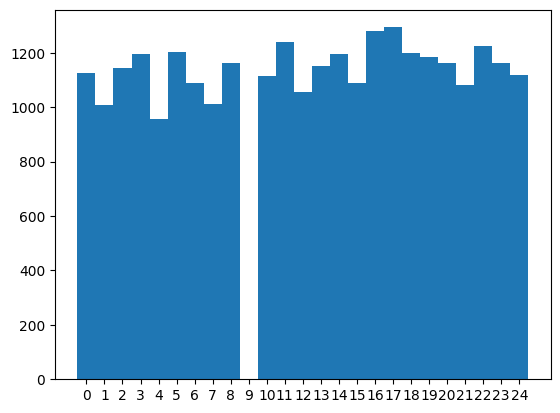

In [ ]:
#distribution of classes
plt.hist(ytrain,bins=np.arange(-0.5,25.5,1))
plt.xticks(np.arange(0,25,1))
plt.show()

In [ ]:
#class y=9 is missing (corresponds to J))
#decrease classes 10-24 by one
ytrain[ytrain>9]=ytrain[ytrain>9]-1
ytest[ytest>9]=ytest[ytest>9]-1

Y=['A','B','C','D','E','F','G','H','I','K','L','M',
   'N','O','P','Q','R','S','T','U','V','W','X','Y']

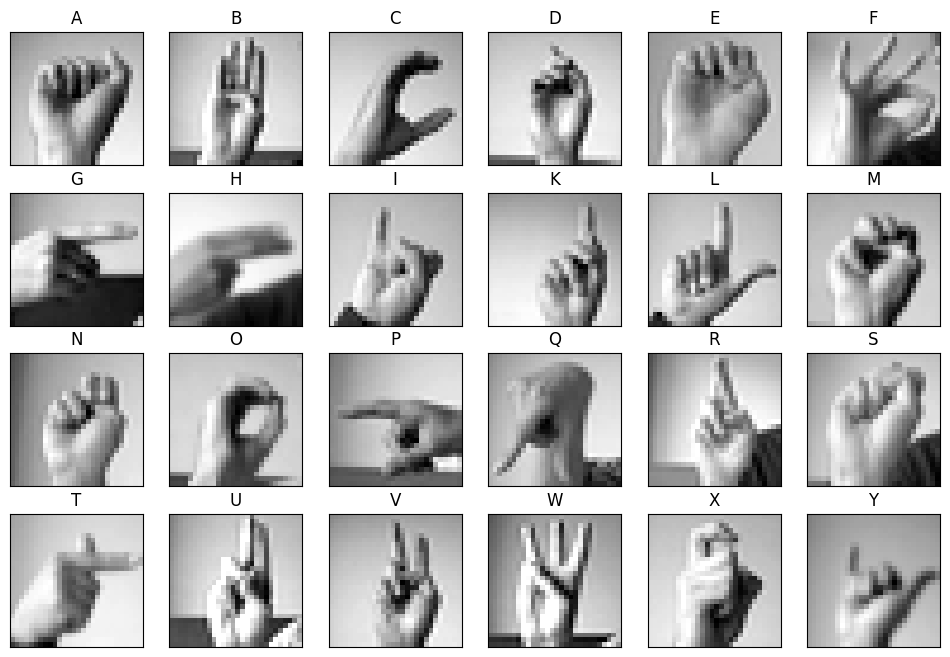

In [ ]:
#example pictures
plt.figure(figsize=(12,8))
for k in range(24):
    xtraink=xtrain[ytrain==k,:]
    mk,nk=xtraink.shape
    indk=rng.integers(mk)
    imgk=xtraink[indk,:].reshape((28,28))
    plt.subplot(4,6,k+1)
    plt.imshow(imgk, cmap='gray')
    plt.xticks([],[])
    plt.yticks([],[])
    plt.title(Y[k])

In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint

N=300

model=Sequential()
model.add(Input(shape=(784,)))
model.add(Dropout(rate=0.2))
model.add(Dense(N,activation='relu'))
model.add(Dropout(rate=0.2))
model.add(Dense(24,activation='softmax'))

model.summary()

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

callback=ModelCheckpoint(
    filepath='sign_mnist_weights.weights.h5',
    monitor='val_accuracy',
    mode='max',
    save_weights_only=True,
    save_best_only=True,
    verbose=1)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dropout_2 (Dropout)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 24)             │         7,224 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,724 (948.14 KB)

 Trainable params: 242,724 (948.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history=model.fit(xtrain,ytrain,
                  epochs=100,
                  batch_size=1000,
                  validation_data=(xtest,ytest),
                  callbacks=[callback])

Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.0838 - loss: 3.2146
Epoch 1: val_accuracy improved from None to 0.33296, saving model to sign_mnist_weights.weights.h5

Epoch 1: finished saving model to sign_mnist_weights.weights.h5
28/28 ━━━━━━━━━━━━━━━━━━━━ 7s 105ms/step - accuracy: 0.1266 - loss: 3.0249 - val_accuracy: 0.3330 - val_loss: 2.5992
Epoch 2/100
26/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2357 - loss: 2.5875
Epoch 2: val_accuracy improved from 0.33296 to 0.43028, saving model to sign_mnist_weights.weights.h5

Epoch 2: finished saving model to sign_mnist_weights.weights.h5
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2693 - loss: 2.4655 - val_accuracy: 0.4303 - val_loss: 2.1360
Epoch 3/100
14/28 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3374 - loss: 2.2058 
Epoch 3: val_accuracy improved from 0.43028 to 0.48982, saving model to sign_mnist_weights.weights.h5

Epoch 3: finished saving model to sign_mnist_weights.weights.h5
28/28 ━━━━━━━

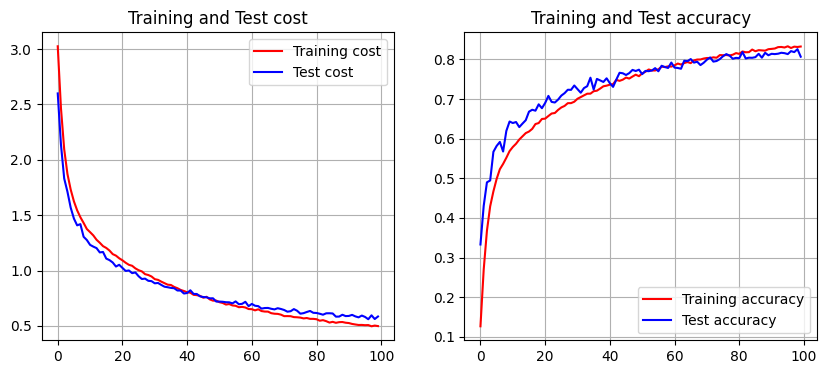

In [ ]:
train_cost=history.history['loss']
test_cost=history.history['val_loss']
train_acc=history.history['accuracy']
test_acc=history.history['val_accuracy']

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_cost,'r',label='Training cost')
plt.plot(test_cost,'b',label='Test cost')
plt.grid()
plt.legend()
plt.title('Training and Test cost')

plt.subplot(1,2,2)
plt.plot(train_acc,'r',label='Training accuracy')
plt.plot(test_acc,'b',label='Test accuracy')
plt.grid()
plt.legend()
plt.title('Training and Test accuracy')

plt.show()

In [ ]:
model.load_weights('sign_mnist_weights.weights.h5')

train_loss,train_acc=model.evaluate(xtrain,ytrain,verbose=0)
test_loss,test_acc=model.evaluate(xtest,ytest,verbose=0)

print('train accuracy =',train_acc)
print('test accuracy =',test_acc)

train accuracy = 0.9874339699745178
test accuracy = 0.8257110714912415


In [ ]:
k=rng.integers(ytest.shape[0])

xt=xtest[k].reshape((1,784))
yt=int(ytest[k])

at_pred=model.predict(xt,verbose=0)
yt_pred=np.argmax(at_pred[0,:])

print('true class =',Y[yt])
print('predicted class =',Y[yt_pred])
print(at_pred)

true class = T
predicted class = T
[[9.9577755e-03 6.4059384e-03 1.3373204e-04 5.4270453e-03 4.6531227e-03
  5.1945364e-03 1.3474031e-02 5.1541518e-02 6.8704590e-02 1.4084808e-03
  7.8327827e-02 1.8533971e-02 9.3381800e-04 5.3883635e-04 1.3479096e-04
  2.6897318e-04 3.2501370e-02 1.7385254e-02 3.5001600e-01 2.3421878e-02
  1.4372309e-01 4.0295813e-02 6.9622085e-03 1.2005538e-01]]


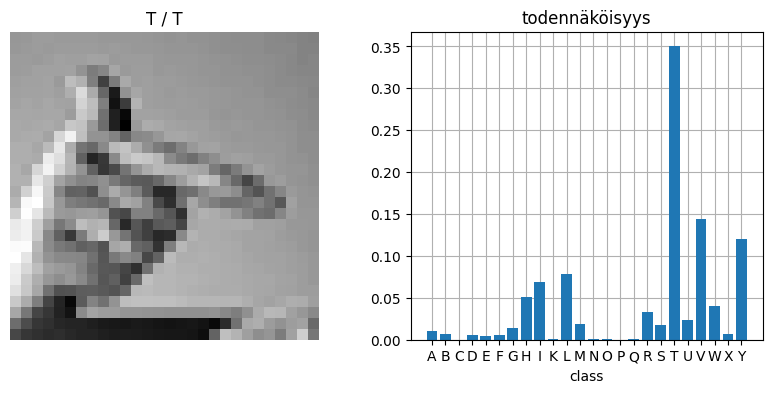

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.imshow(xt.reshape((28,28)),cmap='gray')
plt.title(Y[yt]+' / '+Y[yt_pred])
plt.axis('off')

plt.subplot(1,2,2)
plt.bar(np.arange(24),at_pred[0,:],zorder=2)
plt.xticks(np.arange(24),Y)
plt.xlabel('class')
plt.title('probability')
plt.grid()

plt.show()

## Exercise 5


In [ ]:
#load data/ex5_data.csv
df=pd.read_csv('data/ex5_data.csv')
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

In [ ]:
#remove column Market Category (contains only 8172 values)
df.drop(columns='Market Category',inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Vehicle Size       11914 non-null  object 
 10  Vehicle Style      11914 non-null  object 
 11  highway MPG        11914 non-null  int64  
 12  city mpg           11914 non-null  int64  
 13  Popularity         11914 non-null  int64  
 14  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5), object(7)
memory usage: 1.4+ MB


In [ ]:
#remove rows with missing values
df.dropna(inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11812 entries, 0 to 11913
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11812 non-null  object 
 1   Model              11812 non-null  object 
 2   Year               11812 non-null  int64  
 3   Engine Fuel Type   11812 non-null  object 
 4   Engine HP          11812 non-null  float64
 5   Engine Cylinders   11812 non-null  float64
 6   Transmission Type  11812 non-null  object 
 7   Driven_Wheels      11812 non-null  object 
 8   Number of Doors    11812 non-null  float64
 9   Vehicle Size       11812 non-null  object 
 10  Vehicle Style      11812 non-null  object 
 11  highway MPG        11812 non-null  int64  
 12  city mpg           11812 non-null  int64  
 13  Popularity         11812 non-null  int64  
 14  MSRP               11812 non-null  int64  
dtypes: float64(3), int64(5), object(7)
memory usage: 1.4+ MB


Use Models that have at least 10 representatives and datapoints whose MSRP  $\le$ 100000.

Split datapoints to training and test (70%/30%),
and build and train a neural network with one hidden layer to predict the value  $y$ = MSRP using the other variables such that test mae is $\approx$ 3000.

Draw pictures like below

In [ ]:
#Use Models that have at least 10 representatives
mvc=df['Model'].value_counts()
modelnames=mvc[mvc>=10].index

df2=df.loc[df['Model'].isin(modelnames)].copy()

#Use datapoints whose MSRP <= 100000
df2=df2.loc[df2['MSRP']<=100000].copy()

y=np.array(df2['MSRP'])
df2.drop(columns=['MSRP'],inplace=True)

m,n=df2.shape
print(m)
print(n)
df2.head()

9099
14


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916
5,BMW,1 Series,2012,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916


In [ ]:
#one-hot encoding of the categorical variables (Make, Model, Engine Fuel Type, ...)
X=np.array(pd.get_dummies(df2),dtype=float)
print(X.shape)

#split datapoints to training and test (70%/30%)
from sklearn.model_selection import train_test_split

Xtrain,Xtest,ytrain,ytest=train_test_split(X,y,test_size=0.3,random_state=0)

#normalize training data
mu=np.mean(Xtrain,axis=0)
sigma=np.std(Xtrain,axis=0)
sigma[sigma==0]=1  #columns that are constant in the training data

Xtrain_hat=(Xtrain-mu)/sigma
Xtest_hat=(Xtest-mu)/sigma

print(Xtrain_hat.shape)
print(Xtest_hat.shape)

(9099, 476)
(6369, 476)
(2730, 476)


In [ ]:
#scale outputs
ytrain_hat=ytrain/100000
ytest_hat=ytest/100000

print(np.min(ytrain_hat),np.max(ytrain_hat))
print(np.min(ytest_hat),np.max(ytest_hat))

0.02 0.9995
0.02 0.996


In [ ]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense, Dropout
from keras.optimizers import Adam
from keras.callbacks import ModelCheckpoint

N=512

model=Sequential()
model.add(Input(shape=(Xtrain_hat.shape[1],)))
model.add(Dense(N,activation='tanh'))
model.add(Dropout(0.2))
model.add(Dense(1))

model.summary()

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='mae',
              metrics=['mse'])

callback=ModelCheckpoint(
    filepath='ex5_weights.weights.h5',
    monitor='val_loss',
    mode='min',
    save_weights_only=True,
    save_best_only=True,
    verbose=1)

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 512)            │       244,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,737 (956.00 KB)

 Trainable params: 244,737 (956.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history=model.fit(Xtrain_hat,ytrain_hat,
                  epochs=500,
                  batch_size=1000,
                  validation_data=(Xtest_hat,ytest_hat),
                  callbacks=[callback])

Epoch 1/500
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - loss: 0.1997 - mse: 0.0655
Epoch 1: val_loss improved from None to 0.07563, saving model to ex5_weights.weights.h5

Epoch 1: finished saving model to ex5_weights.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 328ms/step - loss: 0.1698 - mse: 0.0483 - val_loss: 0.0756 - val_mse: 0.0090
Epoch 2/500
1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.1215 - mse: 0.0231
Epoch 2: val_loss improved from 0.07563 to 0.06625, saving model to ex5_weights.weights.h5

Epoch 2: finished saving model to ex5_weights.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 0.1139 - mse: 0.0209 - val_loss: 0.0662 - val_mse: 0.0068
Epoch 3/500
1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.1064 - mse: 0.0177
Epoch 3: val_loss improved from 0.06625 to 0.04961, saving model to ex5_weights.weights.h5

Epoch 3: finished saving model to ex5_weights.weights.h5
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.1043 - mse: 0.0176 - val_loss: 0.0496 - val_mse: 0.0042
Epoch

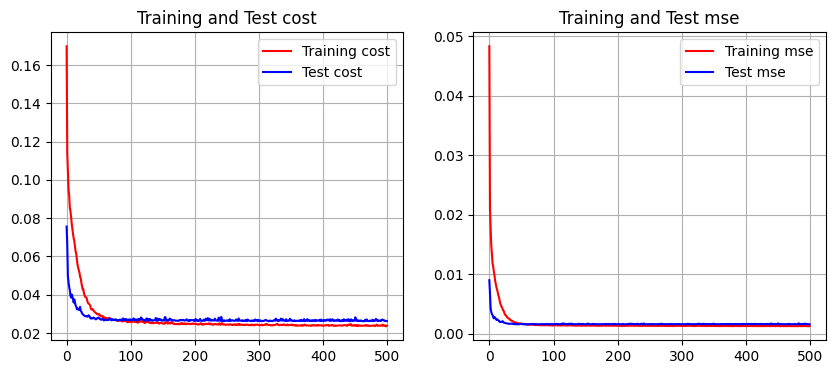

In [ ]:
train_cost=history.history['loss']
test_cost=history.history['val_loss']
train_mse=history.history['mse']
test_mse=history.history['val_mse']

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(train_cost,'r',label='Training cost')
plt.plot(test_cost,'b',label='Test cost')
plt.grid()
plt.legend()
plt.title('Training and Test cost')

plt.subplot(1,2,2)
plt.plot(train_mse,'r',label='Training mse')
plt.plot(test_mse,'b',label='Test mse')
plt.grid()
plt.legend()
plt.title('Training and Test mse')

plt.show()

In [ ]:
model.load_weights('ex5_weights.weights.h5')

train_mae,train_mse=model.evaluate(Xtrain_hat,ytrain_hat,verbose=0)
test_mae,test_mse=model.evaluate(Xtest_hat,ytest_hat,verbose=0)

print('train mae =',train_mae*100000)
print('test mae =',test_mae*100000)

train mae = 2289.7757589817047
test mae = 2610.844746232033


In [ ]:
ytrain_pred=model.predict(Xtrain_hat,verbose=0)*100000
ytest_pred=model.predict(Xtest_hat,verbose=0)*100000

print(ytrain_pred.shape)
print(ytest_pred.shape)

(6369, 1)
(2730, 1)


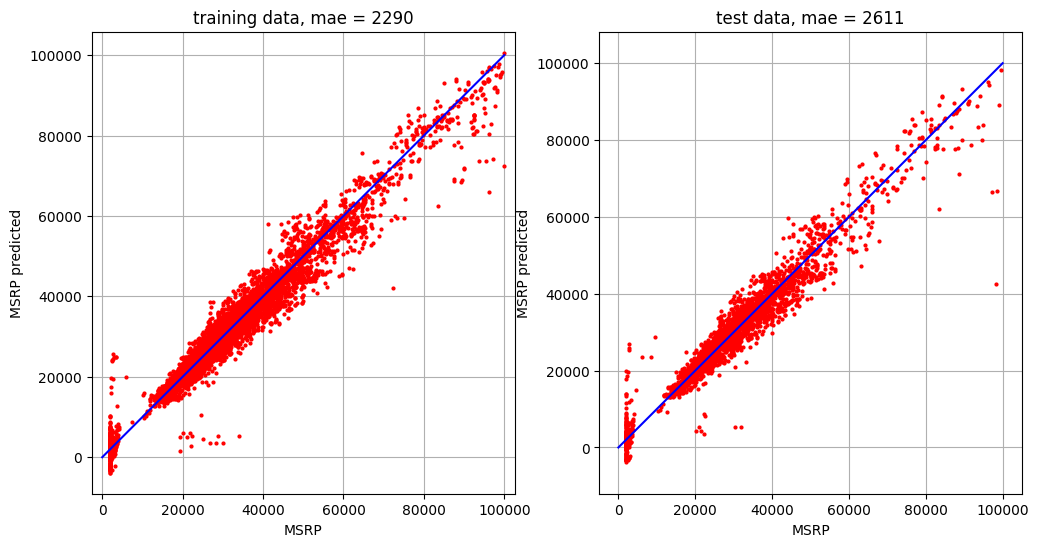

In [ ]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.plot(ytrain,ytrain_pred[:,0],'r.',markersize=4)
plt.plot([0,100000],[0,100000],'b')
plt.grid()
plt.axis('equal')
plt.title('training data, mae = {:.0f}'.format(train_mae*100000))
plt.xlabel('MSRP')
plt.ylabel('MSRP predicted')

plt.subplot(1,2,2)
plt.plot(ytest,ytest_pred[:,0],'r.',markersize=4)
plt.plot([0,100000],[0,100000],'b')
plt.grid()
plt.axis('equal')
plt.title('test data, mae = {:.0f}'.format(test_mae*100000))
plt.xlabel('MSRP')
plt.ylabel('MSRP predicted')

plt.show()

![figure](images/04_ex5_1.png)